# 02 · Profitability Analysis

**Business problem:** the company is growing sales every year, but profit margin is not keeping up. Management wants to know **where the profit is leaking and what to change.**

| # | Business question |
|---|---|
| 1 | How have sales, profit and margin trended, and is there seasonality? |
| 2 | Which categories and sub-categories lose money? |
| 3 | At what discount level does a sale become unprofitable? |
| 4 | Which regions and states drive or drain profit? |
| 5 | Which customer segment earns the most profit per order? |
| 6 | If discounts were capped, how much profit could be recovered? |

Input: `data/processed/superstore_clean.csv` (built in notebook 01).

In [1]:
import duckdb
import pandas as pd
from pathlib import Path

# Work out the project root whether the notebook runs from /notebooks or the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = (ROOT / "data" / "raw" / "superstore.csv").as_posix()
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

CLEAN = (PROCESSED / "superstore_clean.csv").as_posix()
con.sql(f"CREATE OR REPLACE TABLE orders AS SELECT * FROM read_csv_auto('{CLEAN}')")
q = lambda sql: con.sql(sql).df()

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#52514e", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 10,
})
money = mtick.FuncFormatter(lambda x, _: f"-${abs(x)/1000:,.0f}k" if x < 0 else f"${x/1000:,.0f}k")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMAGES / name, dpi=150, bbox_inches="tight")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## Headline numbers

In [3]:
q("""
    SELECT ROUND(SUM(sales))                        AS total_sales,
           ROUND(SUM(profit))                       AS total_profit,
           ROUND(100 * SUM(profit) / SUM(sales), 1) AS margin_pct,
           COUNT(DISTINCT order_id)                 AS orders,
           COUNT(DISTINCT customer_id)              AS customers,
           ROUND(100 * AVG(is_loss::INT), 1)        AS pct_lines_loss_making
    FROM orders
""")

,total_sales,total_profit,margin_pct,orders,customers,pct_lines_loss_making
0,"2,296,919.00","286,409.00",12.50,5009,793,18.70


## Q1 · Trend: sales grow, margin stalls

`LAG()` is a window function. It brings the previous year's value onto the current row, so year-on-year growth can be calculated in one query.

In [4]:
yearly = q("""
    WITH y AS (
        SELECT order_year, SUM(sales) AS sales, SUM(profit) AS profit
        FROM orders GROUP BY order_year
    )
    SELECT order_year,
           ROUND(sales)                                                       AS sales,
           ROUND(profit)                                                      AS profit,
           ROUND(100 * profit / sales, 1)                                     AS margin_pct,
           ROUND(100 * (sales / LAG(sales) OVER (ORDER BY order_year) - 1), 1) AS sales_growth_pct
    FROM y ORDER BY order_year
""")
yearly

,order_year,sales,profit,margin_pct,sales_growth_pct
0,2014,"483,966.00","49,556.00",10.20,NaN
1,2015,"470,533.00","61,619.00",13.10,-2.80
2,2016,"609,206.00","81,795.00",13.40,29.50
3,2017,"733,215.00","93,439.00",12.70,20.40


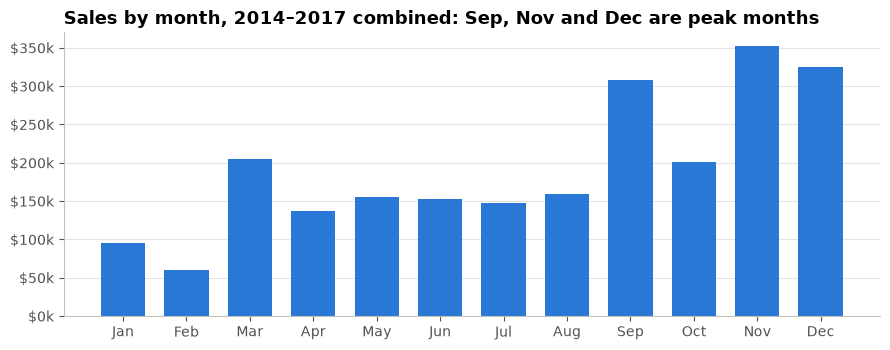

In [5]:
monthly = q("""
    SELECT month(order_date) AS month, ROUND(SUM(sales)) AS sales
    FROM orders GROUP BY 1 ORDER BY 1
""")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(monthly["month"], monthly["sales"], color=BLUE, width=0.7)
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(money)
ax.set_title("Sales by month, 2014–2017 combined: Sep, Nov and Dec are peak months")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
save(fig, "01_monthly_seasonality.png")

**Insight:** sales grew about 51% from 2014 to 2017, but margin stayed around 12–13% and fell in 2017. Sales are heavily seasonal: September, November and December together bring in ~43% of annual revenue, so stock and staffing should be planned around Q4.

## Q2 · Which products lose money?

In [6]:
subcat = q("""
    SELECT category, sub_category,
           ROUND(SUM(sales))                        AS sales,
           ROUND(SUM(profit))                       AS profit,
           ROUND(100 * SUM(profit) / SUM(sales), 1) AS margin_pct,
           ROUND(100 * AVG(discount), 1)            AS avg_discount_pct
    FROM orders
    GROUP BY ALL
    ORDER BY profit
""")
subcat

,category,sub_category,sales,profit,margin_pct,avg_discount_pct
0,Furniture,Tables,"206,966.00","-17,725.00",-8.60,26.10
1,Furniture,Bookcases,"114,880.00","-3,473.00",-3.00,21.10
2,Office Supplies,Supplies,"46,674.00","-1,189.00",-2.50,7.70
3,Office Supplies,Fasteners,"3,024.00",950.00,31.40,8.20
4,Technology,Machines,"189,239.00","3,385.00",1.80,30.60
5,Office Supplies,Labels,"12,486.00","5,546.00",44.40,6.90
6,Office Supplies,Art,"27,119.00","6,528.00",24.10,7.50
7,Office Supplies,Envelopes,"16,476.00","6,964.00",42.30,8.00
8,Furniture,Furnishings,"91,705.00","13,059.00",14.20,13.80
9,Office Supplies,Appliances,"107,532.00","18,138.00",16.90,16.70


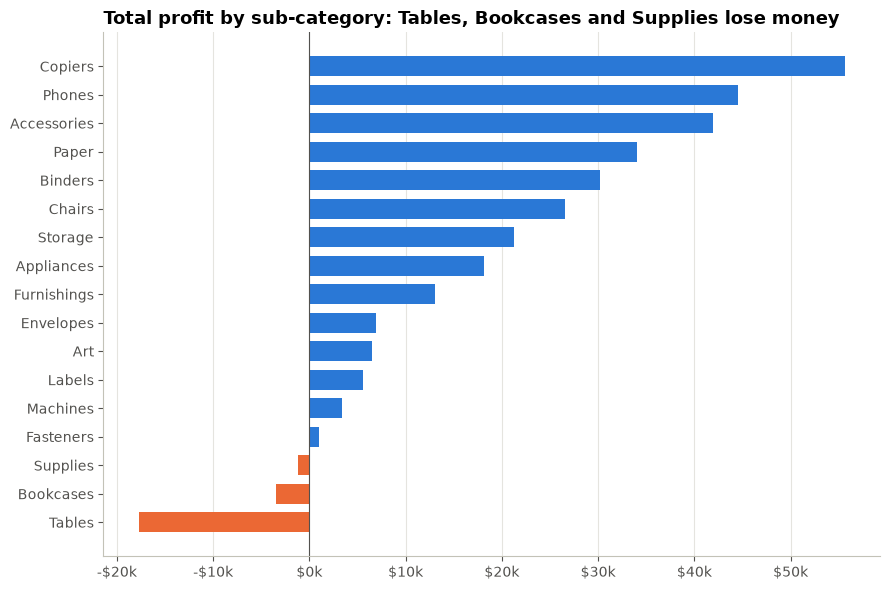

In [7]:
s = subcat.sort_values("profit")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(s["sub_category"], s["profit"], color=[ORANGE if p < 0 else BLUE for p in s["profit"]], height=0.7)
ax.axvline(0, color=GREY, linewidth=0.8)
ax.xaxis.set_major_formatter(money)
ax.set_title("Total profit by sub-category: Tables, Bookcases and Supplies lose money")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
save(fig, "02_profit_by_subcategory.png")

**Insight:** Furniture brings in about a third of revenue but has only a **2.5% margin**, compared with ~17% for Technology and Office Supplies. **Tables** alone lose ~$17.7k at an average discount of 26%. Copiers, Phones and Accessories earn the most profit.

## Q3 · Where does discounting stop paying off?

In [8]:
bands = q("""
    SELECT discount_band,
           COUNT(*)                                 AS order_lines,
           ROUND(SUM(sales))                        AS sales,
           ROUND(SUM(profit))                       AS profit,
           ROUND(100 * SUM(profit) / SUM(sales), 1) AS margin_pct,
           ROUND(100 * AVG(is_loss::INT), 1)        AS pct_lines_at_a_loss
    FROM orders
    GROUP BY discount_band
    ORDER BY MIN(discount)
""")
bands

,discount_band,order_lines,sales,profit,margin_pct,pct_lines_at_a_loss
0,0%,4798,"1,087,908.00","320,988.00",29.50,0.00
1,1-20%,3803,"846,522.00","100,785.00",11.90,13.80
2,21-30%,226,"102,945.00","-10,357.00",-10.10,91.60
3,31-50%,310,"195,315.00","-48,448.00",-24.80,91.60
4,51-80%,856,"64,229.00","-76,559.00",-119.20,100.00


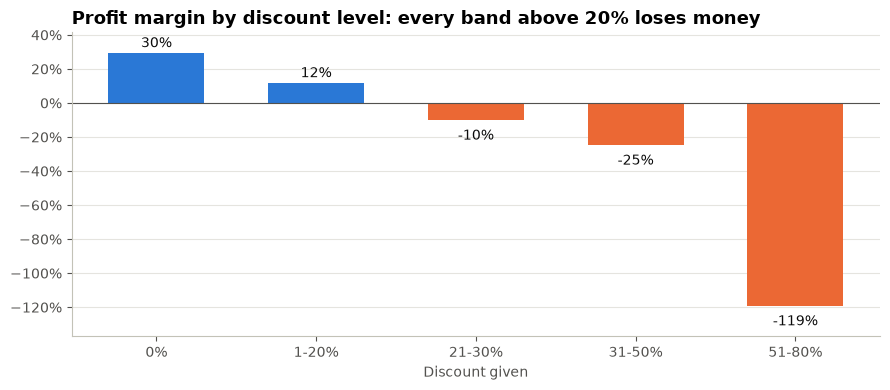

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(bands["discount_band"], bands["margin_pct"],
       color=[ORANGE if m < 0 else BLUE for m in bands["margin_pct"]], width=0.6)
ax.axhline(0, color=GREY, linewidth=0.8)
for x, m in zip(bands["discount_band"], bands["margin_pct"]):
    ax.annotate(f"{m:.0f}%", (x, m), xytext=(0, 4 if m >= 0 else -14), textcoords="offset points",
                ha="center", color=INK, fontsize=10)
ax.set_ylim(bands["margin_pct"].min() - 18, bands["margin_pct"].max() + 12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Discount given")
ax.set_title("Profit margin by discount level: every band above 20% loses money")
ax.grid(axis="y", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
save(fig, "03_margin_by_discount.png")

**Insight:** this is the core finding. Up to 20% discount, sales stay profitable. **Above 20%, over 90% of order lines lose money**, and above 50% the company loses more than it takes in. The **20% threshold** is the line to manage.

## Q4 · Regions and states

`RANK()` orders states inside each region without collapsing the rows the way `GROUP BY` would.

In [10]:
q("""
    SELECT region,
           ROUND(SUM(sales))                        AS sales,
           ROUND(SUM(profit))                       AS profit,
           ROUND(100 * SUM(profit) / SUM(sales), 1) AS margin_pct,
           ROUND(100 * AVG(discount), 1)            AS avg_discount_pct
    FROM orders GROUP BY region ORDER BY margin_pct
""")

,region,sales,profit,margin_pct,avg_discount_pct
0,Central,"501,240.00","39,706.00",7.90,24.00
1,South,"391,722.00","46,749.00",11.90,14.70
2,East,"678,500.00","91,535.00",13.50,14.50
3,West,"725,458.00","108,418.00",14.90,10.90


In [11]:
states = q("""
    WITH s AS (
        SELECT region, state, SUM(sales) AS sales, SUM(profit) AS profit, AVG(discount) AS avg_discount
        FROM orders GROUP BY region, state
    )
    SELECT region, state,
           ROUND(sales)                 AS sales,
           ROUND(profit)                AS profit,
           ROUND(100 * avg_discount, 1) AS avg_discount_pct,
           RANK() OVER (PARTITION BY region ORDER BY profit) AS worst_in_region
    FROM s
    ORDER BY profit
""")
states.head(8)

,region,state,sales,profit,avg_discount_pct,worst_in_region
0,Central,Texas,"170,188.00","-25,729.00",37.00,1
1,East,Ohio,"77,977.00","-16,959.00",32.50,1
2,East,Pennsylvania,"116,512.00","-15,560.00",32.90,2
3,Central,Illinois,"80,166.00","-12,608.00",39.00,2
4,South,North Carolina,"55,603.00","-7,491.00",28.40,1
5,West,Colorado,"32,108.00","-6,528.00",31.60,1
6,South,Tennessee,"30,662.00","-5,342.00",29.10,2
7,West,Arizona,"35,282.00","-3,428.00",30.40,2


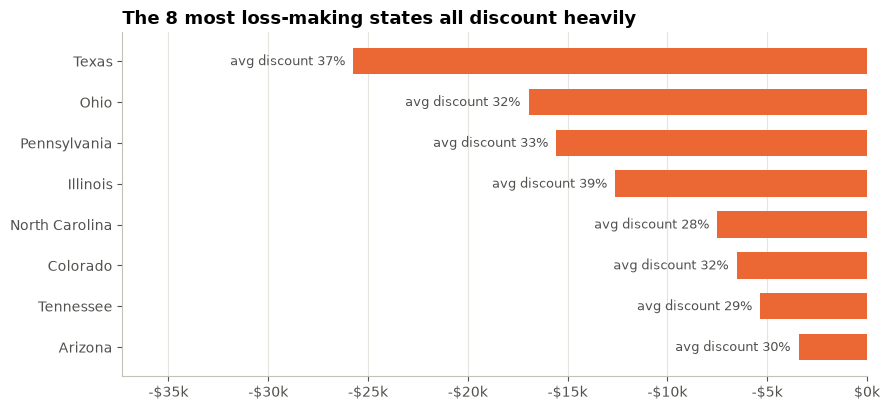

In [12]:
w = states.head(8).sort_values("profit", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(w["state"], w["profit"], color=ORANGE, height=0.65)
for y, (p, d) in enumerate(zip(w["profit"], w["avg_discount_pct"])):
    ax.annotate(f"avg discount {d:.0f}%", (p, y), xytext=(-6, 0), textcoords="offset points",
                ha="right", va="center", color=GREY, fontsize=9)
ax.set_xlim(w["profit"].min() * 1.45, 0)
ax.xaxis.set_major_formatter(money)
ax.set_title("The 8 most loss-making states all discount heavily")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8); ax.set_axisbelow(True)
save(fig, "04_loss_making_states.png")

**Insight:** Central is the weakest region (7.9% margin) and also discounts the most (24% on average). **Texas, Ohio, Pennsylvania and Illinois** together lose about **$71k**, all with average discounts of 32–39%. California and New York earn about $150k between them at low discount levels. The problem is discount policy in specific states, not demand.

## Q5 · Customer segments

In [13]:
q("""
    WITH order_totals AS (
        SELECT segment, order_id, SUM(sales) AS order_sales, SUM(profit) AS order_profit
        FROM orders GROUP BY segment, order_id
    )
    SELECT segment,
           COUNT(*)                                             AS orders,
           ROUND(AVG(order_sales), 2)                           AS avg_order_value,
           ROUND(AVG(order_profit), 2)                          AS profit_per_order,
           ROUND(100 * SUM(order_profit) / SUM(order_sales), 1) AS margin_pct
    FROM order_totals
    GROUP BY segment ORDER BY profit_per_order DESC
""")

,segment,orders,avg_order_value,profit_per_order,margin_pct
0,Home Office,909,472.36,66.35,14.00
1,Corporate,1514,466.41,60.75,13.00
2,Consumer,2586,449.11,51.86,11.50


**Insight:** Consumer is the biggest segment by volume, but **Home Office** earns the most per order (about $66 vs $52) and the best margin. It is a good target for growth campaigns.

## Q6 · What if discounts were capped at 20%?

Two scenarios give a **range** rather than a single, overconfident number:

- **Best case:** customers still buy at a 20% discount, so revenue moves from the deep-discount price to the 20%-off price.
- **Worst case:** every customer who was offered >20% walks away, so those sales *and* their losses disappear.

In [14]:
scenario = q("""
    WITH deep AS (
        SELECT * FROM orders WHERE discount > 0.2
    )
    SELECT COUNT(*)                                            AS lines_above_20pct,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 1) AS pct_of_all_lines,
           ROUND(SUM(sales))                                   AS sales_affected,
           ROUND(SUM(profit))                                  AS current_profit_on_them,
           ROUND(-SUM(profit))                                 AS worst_case_gain,
           ROUND(SUM(list_price_sales * 0.8 - sales))          AS best_case_gain
    FROM deep
""")
scenario

,lines_above_20pct,pct_of_all_lines,sales_affected,current_profit_on_them,worst_case_gain,best_case_gain
0,1392,13.90,"362,489.00","-135,364.00","135,364.00","219,151.00"


In [15]:
total_profit = q("SELECT SUM(profit) AS p FROM orders")["p"][0]
lo, hi = scenario["worst_case_gain"][0], scenario["best_case_gain"][0]
print(f"Current profit: ${total_profit:,.0f}")
print(f"Capping discounts at 20% would add ${lo:,.0f} to ${hi:,.0f} "
      f"(+{100*lo/total_profit:.0f}% to +{100*hi/total_profit:.0f}%)")

Current profit: $286,409
Capping discounts at 20% would add $135,364 to $219,151 (+47% to +77%)


**Insight:** only ~14% of order lines carry a discount above 20%, but they lose about $135k. Capping discounts at 20% would raise profit by about **$135k–$219k (+47% to +77%)**. Even the cautious scenario increases profit by almost half.

*Assumptions:* product cost stays the same, and the best case assumes volume holds. A real roll-out should be tested on one region first (for example Central or Texas) before going company-wide.

## Recommendations

1. **Cap standard discounts at 20%.** Anything higher needs manager approval and a margin check.
2. **Review Furniture pricing**, starting with **Tables and Bookcases**. Raise prices, cut discounts or renegotiate supplier cost.
3. **Pilot the cap in Texas, Ohio, Pennsylvania and Illinois**, where deep discounts cost about $71k.
4. **Grow Home Office and Technology**, which have the highest profit per order and the highest margins.
5. **Plan stock and promotions around Sep, Nov and Dec**, when about 43% of revenue lands, without deep discounting.